# 2. Growing Toward the Right Inputs

> **Overview.** A new LTU rarely reads all of its feature's inputs. What does it learn with only some of them, and can
> it find the rest?

**Setup.** Notebook 1's target and LTUs, added later with initial step-size $3 \times 10^{-2}$. Each LTU reads $j$ = 2,
4, 6 or 8 of its target LTU's 10 inputs, drawn at random. 5 seeds; 600k steps.
- **2a.** Without growth.
- **2b.** With *growth*: each LTU sums the gradient that each input it does not read would get, and every 1k steps
  connects the input whose sum stands out.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of the LTUs' input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps before LTUs added later
NUM_STEPS = 500_000                  # steps after that
NEVER = LINEAR_STEPS + NUM_STEPS     # LTUs added at NEVER: the linear learner alone
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

Notebook 1's learner. New here: `learn` also sums each LTU's gradients on the inputs it does not read, and `grow`
connects the one that stands out.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection


def init_net(key, target, right):
    # Each pair of LTUs wired like one target LTU in turn, but reading only `right` of its inputs, drawn at random, and
    # the bias, with LeCun uniform weights over their fan-in; their shadow weights +1 and -1, on a random output that
    # reads that target LTU. Every other weight 0.
    w_key, right_key, out_key = jax.random.split(key, 3)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    target_inputs = target.w[assigned] != 0
    kept = jnp.argsort(jnp.argsort(jnp.where(target_inputs, jax.random.uniform(right_key, target_inputs.shape), jnp.inf)))
    reads = jnp.append(target_inputs & (kept < right), jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = right
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and the squared error on this sample averaged over the outputs, before learning from it,
    # and adds dL/dz * x_i to each LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean)

    (loss, (source, h, mean)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), 2 * loss / N_OUTPUTS


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, add_step, grows):
    # NEVER online network-Autostep steps on samples from `target`, the LTUs added at add_step, each growing every
    # WINDOW steps after that if grows. Returns each window's mean squared error.
    def window(net, inputs):
        index, key = inputs
        net = pick(index * WINDOW == add_step, add(net), net)
        net, mse = jax.lax.scan(lambda net, k: learn(net, *sample(target, k)), net, jax.random.split(key, WINDOW))
        net = pick(grows & ((index + 1) * WINDOW > add_step), grow(net), net)
        return net, mse.mean()

    n = NEVER // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (add_step, right, grows) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same
    # target network and samples. Returns {config: the RMSE of each window, shaped (seed, window)}.
    add_step, right, grows, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets, right)
    mse = jax.jit(jax.vmap(train))(nets, keys(1), targets, add_step, grows)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
RIGHT = (2, 4, 6, 8)
TOO_FEW = {j: (LINEAR_STEPS, j, False) for j in RIGHT}
GROWING = {j: (LINEAR_STEPS, j, True) for j in RIGHT}
REFERENCE, LINEAR = (LINEAR_STEPS, N_SOURCES, False), (NEVER, N_SOURCES, False)
started = perf_counter()
rmse = run([*TOO_FEW.values(), *GROWING.values(), REFERENCE, LINEAR])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

50 runs in 104s


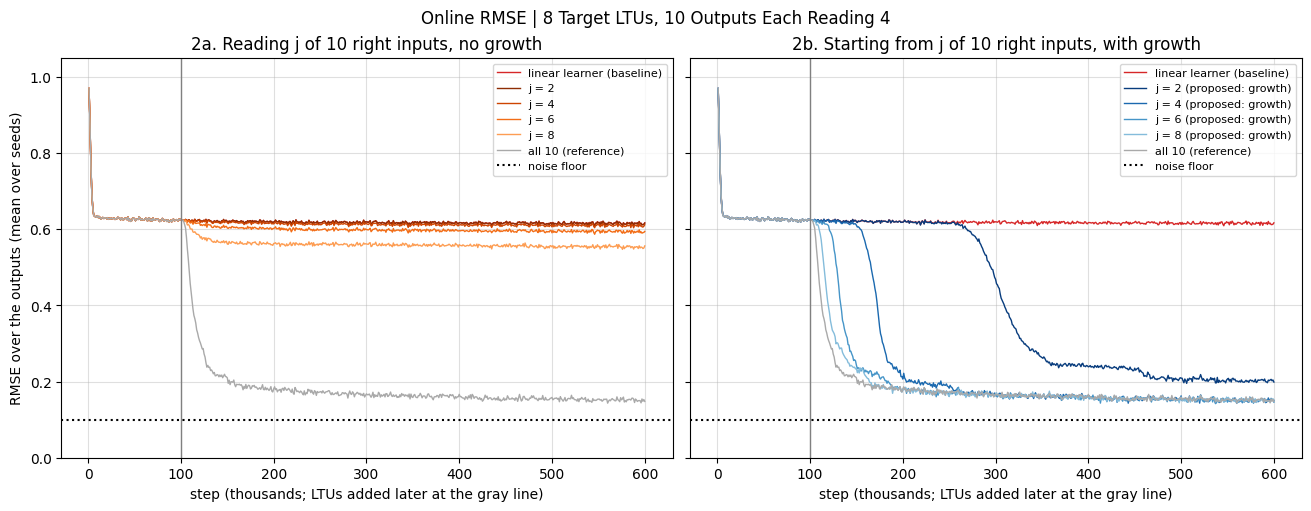

In [7]:
STEPS = (np.arange(NEVER // WINDOW) + 1) * WINDOW


def plot(ax, curves, title):
    # The linear learner, then each (label, config, color) of curves, and the noise floor: the mean RMSE over seeds.
    for label, config, color in [('linear learner (baseline)', LINEAR, 'tab:red')] + curves:
        ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step (thousands; LTUs added later at the gray line)', ylim=(0, 1.05), title=title)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, layout='constrained')
reference = [(f'all {N_SOURCES} (reference)', REFERENCE, 'darkgray')]
plot(axes[0], [(f'j = {j}', TOO_FEW[j], plt.cm.Oranges(0.95 - 0.17 * i)) for i, j in enumerate(RIGHT)] + reference,
     f'2a. Reading j of {N_SOURCES} right inputs, no growth')
plot(axes[1], [(f'j = {j} (proposed: growth)', GROWING[j], plt.cm.Blues(0.95 - 0.17 * i)) for i, j in enumerate(RIGHT)]
     + reference, f'2b. Starting from j of {N_SOURCES} right inputs, with growth')
axes[0].set_ylabel('RMSE over the outputs (mean over seeds)')
fig.suptitle(f'Online RMSE | {N_TARGETS} Target LTUs, {N_OUTPUTS} Outputs Each Reading {OUTPUT_FAN_IN}')
plt.show()

## Results

- **2a.** An LTU with only some of its feature's inputs learns nothing: the linear learner already holds almost all
  that a partial feature shares with the target.
- **2b.** Growth completes an LTU that starts from 4 or more right inputs, because the gradient on a missing right
  input grows with how much of the feature the LTU already holds.

## Details

**Growth.** For each input $i$ it does not read, an LTU sums $\partial L/\partial z \cdot x_i$, the gradient that
input's weight would get, where $z$ is the LTU's pre-activation. Every 1k steps, it connects the input with the largest
sum in magnitude, if that sum is more than 6 times the root mean square of the sums, at weight 0 and step-size
$3 \times 10^{-2}$, and then restarts its sums.

**Right inputs are rare.** $k$ inputs drawn at random hold on average $k/100$ of a given target LTU's 10, and all 10
essentially never.

**The reference** is notebook 1's LTUs at step-size $3 \times 10^{-2}$, reading all 10 right inputs.